# HI5312 — Module 6: Group Project Studio

**Purpose:** This module is a project workspace. It does not introduce new technical content. It helps your group organize, document, complete, and present your health informatics group project.

**Course framework:** Better Questions → Better Data → Better Analysis → Better Decisions → Better Health

**Tools used:** GitHub, GitHub Codespaces, PostgreSQL, SQL, Python 3.12.12, pandas, Tableau, and PowerPoint.

## Clinical Request

Your team has been asked by a healthcare leadership group to answer an important clinical or operational question using the approved course dataset. Your final product should be reproducible, clearly documented, and understandable to a healthcare audience.

Your job is to turn a broad healthcare problem into a clear question, acquire and prepare the data, analyze it responsibly, visualize the findings, and present a recommendation.

## Student Learning Goals

By completing the Group Project, your team will demonstrate that you can:

- define a healthcare analytics question;
- identify relevant data sources and variables;
- write SQL to retrieve and summarize data;
- use Python to clean, validate, and explore data;
- create a Tableau dashboard that communicates findings;
- document assumptions and limitations;
- collaborate as a project team; and
- present findings to a professional audience.

## Group Project Workflow

Use this notebook as the central project workspace.

1. Define the question.
2. Identify tables, variables, and cohort criteria.
3. Write SQL extraction and validation queries.
4. Load the results into Python.
5. Clean and document the dataset.
6. Explore patterns and create summary tables.
7. Export Tableau-ready files.
8. Build the dashboard.
9. Prepare the final presentation.
10. Submit the final project package.

## Team Information

**Team name:**  

**Team members:**  

**Project title:**  

**Primary stakeholder:**  

**Dataset:**  

**Primary clinical or operational question:**

## Project Charter

Complete this section before starting the technical work.

| Section | Team Response |
|---|---|
| Background |  |
| Problem statement |  |
| Primary question |  |
| Intended audience |  |
| Unit of analysis |  |
| Key variables |  |
| Expected deliverables |  |
| Major risks or limitations |  |
| Team roles |  |

## Milestone Tracker

Use this checklist to monitor progress.

- [ ] Project question approved
- [ ] Relevant tables identified
- [ ] SQL extraction query drafted
- [ ] SQL validation queries completed
- [ ] Python notebook started
- [ ] Data cleaning decisions documented
- [ ] Exploratory summaries completed
- [ ] Tableau-ready CSV exported
- [ ] Tableau dashboard draft completed
- [ ] Presentation draft completed
- [ ] README updated
- [ ] Final files submitted

## Database Connection

The course PostgreSQL database runs inside Codespaces.

| Setting | Value |
|---|---|
| Host | `db` |
| Port | `5432` |
| Database | `hi5304` |
| Username | `hi5304_user` |
| Password | `hi5304` |

These credentials are intentionally simple for coursework only. Do not reuse them in real systems.

In [2]:
# Verify the Python environment
import sys
print(sys.version)

3.12.13 (main, Jun 24 2026, 04:58:38) [GCC 12.2.0]


In [3]:
# Import project packages
import os
from pathlib import Path
from urllib.parse import quote_plus

import pandas as pd
from sqlalchemy import create_engine, text

pd.set_option("display.max_columns", 50)

In [4]:
# Connect to the course PostgreSQL database
pg_host = os.getenv("PGHOST", "db")
pg_port = os.getenv("PGPORT", "5432")
pg_database = os.getenv("PGDATABASE", "hi5304")
pg_user = os.getenv("PGUSER", "hi5304_user")
pg_password = os.getenv("PGPASSWORD", "hi5304")

connection_url = (
    f"postgresql+psycopg://{pg_user}:{quote_plus(pg_password)}"
    f"@{pg_host}:{pg_port}/{pg_database}"
)

engine = create_engine(connection_url, pool_pre_ping=True)

with engine.connect() as connection:
    result = connection.execute(text("SELECT current_database(), current_user;"))
    print(result.fetchone())

('hi5304', 'hi5304_user')


In [ ]:
# Helper function for SQL queries
# Use text() so LIKE patterns with % work reliably.
def read_query(sql: str) -> pd.DataFrame:
    return pd.read_sql(text(sql), engine)

## Step 1 — Inspect Available Schemas and Tables

Use this section to identify the tables your project might need.

In [6]:
def read_query(sql: str) -> pd.DataFrame:
    return pd.read_sql(text(sql), engine)

In [7]:
schema_query = """
SELECT schema_name
FROM information_schema.schemata
WHERE schema_name LIKE 'mimiciv%'
ORDER BY schema_name;
"""

read_query(schema_query)

,schema_name
0,mimiciv_derived
1,mimiciv_hosp
2,mimiciv_icu


In [8]:
tables_query = """
SELECT table_schema, table_name
FROM information_schema.tables
WHERE table_schema LIKE 'mimiciv%'
ORDER BY table_schema, table_name;
"""

read_query(tables_query)

,table_schema,table_name
0,mimiciv_hosp,admissions
1,mimiciv_hosp,d_hcpcs
2,mimiciv_hosp,d_icd_diagnoses
3,mimiciv_hosp,d_icd_procedures
4,mimiciv_hosp,d_labitems
5,mimiciv_hosp,diagnoses_icd
6,mimiciv_hosp,drgcodes
7,mimiciv_hosp,emar
8,mimiciv_hosp,emar_detail
9,mimiciv_hosp,hcpcsevents


## Step 2 — Select Project Tables

List the tables your team plans to use.

| Table | Why it is needed | Key fields |
|---|---|---|
|  |  |  |
|  |  |  |
|  |  |  |

In [9]:
# Optional: inspect columns in a selected table
selected_schema = "mimiciv_hosp"
selected_table = "patients"

columns_query = f"""
SELECT column_name, data_type
FROM information_schema.columns
WHERE table_schema = '{selected_schema}'
  AND table_name = '{selected_table}'
ORDER BY ordinal_position;
"""

read_query(columns_query)

,column_name,data_type
0,subject_id,integer
1,gender,character
2,anchor_age,smallint
3,anchor_year,smallint
4,anchor_year_group,character varying
5,dod,date


## Step 3 — SQL Workspace

Write your extraction query below. Keep validation queries separate from your final extraction query.

In [10]:
# Draft extraction query
project_sql = """
-- Replace this query with your project query.
SELECT
    p.subject_id,
    p.gender,
    p.anchor_age,
    a.hadm_id,
    a.admittime,
    a.dischtime,
    a.admission_type
FROM mimiciv_hosp.patients AS p
JOIN mimiciv_hosp.admissions AS a
    ON p.subject_id = a.subject_id
LIMIT 20;
"""

project_df = read_query(project_sql)
project_df.head()

,subject_id,gender,anchor_age,hadm_id,admittime,dischtime,admission_type
0,10004235,M,47,24181354,2196-02-24 14:38:00,2196-03-04 14:02:00,URGENT
1,10009628,M,58,25926192,2153-09-17 17:08:00,2153-09-25 13:20:00,URGENT
2,10018081,M,79,23983182,2134-08-18 02:02:00,2134-08-23 19:35:00,URGENT
3,10006053,M,52,22942076,2111-11-13 23:39:00,2111-11-15 17:20:00,URGENT
4,10031404,F,82,21606243,2113-08-04 18:46:00,2113-08-06 20:57:00,URGENT


## Step 4 — SQL Validation Queries

Use validation queries to confirm counts, row uniqueness, missingness, and expected table relationships.

In [11]:
# Validation example: row count
validation_count_query = """
SELECT COUNT(*) AS row_count
FROM mimiciv_hosp.admissions;
"""

read_query(validation_count_query)

,row_count
0,550


In [12]:
# Validation example: duplicate key review
# Modify the table and key to match your project.
duplicate_review_query = """
SELECT hadm_id, COUNT(*) AS row_count
FROM mimiciv_hosp.admissions
GROUP BY hadm_id
HAVING COUNT(*) > 1
ORDER BY row_count DESC;
"""

read_query(duplicate_review_query)

,hadm_id,row_count
0,24294180,2
1,28984460,2
2,22732862,2
3,26706939,2
4,25973915,2
...,...,...
270,23112364,2
271,28829452,2
272,20282368,2
273,28778757,2


## Step 5 — Load the Project Dataset into Python

Once the SQL extraction query is ready, load the result into a pandas DataFrame.

In [13]:
project_df = read_query(project_sql)

print("Rows:", project_df.shape[0])
print("Columns:", project_df.shape[1])
project_df.head()

Rows: 20
Columns: 7


,subject_id,gender,anchor_age,hadm_id,admittime,dischtime,admission_type
0,10004235,M,47,24181354,2196-02-24 14:38:00,2196-03-04 14:02:00,URGENT
1,10009628,M,58,25926192,2153-09-17 17:08:00,2153-09-25 13:20:00,URGENT
2,10018081,M,79,23983182,2134-08-18 02:02:00,2134-08-23 19:35:00,URGENT
3,10006053,M,52,22942076,2111-11-13 23:39:00,2111-11-15 17:20:00,URGENT
4,10031404,F,82,21606243,2113-08-04 18:46:00,2113-08-06 20:57:00,URGENT


In [14]:
project_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   subject_id      20 non-null     int64         
 1   gender          20 non-null     str           
 2   anchor_age      20 non-null     int64         
 3   hadm_id         20 non-null     int64         
 4   admittime       20 non-null     datetime64[us]
 5   dischtime       20 non-null     datetime64[us]
 6   admission_type  20 non-null     str           
dtypes: datetime64[us](2), int64(3), str(2)
memory usage: 1.2 KB


## Step 6 — Data Cleaning Log

Document every data cleaning decision. Do not clean silently.

| Date | Variable | Issue | Decision | Rationale | Team member |
|---|---|---|---|---|---|
|  |  |  |  |  |  |

In [15]:
# Basic data quality review
missing_summary = (
    project_df.isna()
    .sum()
    .rename("missing_count")
    .to_frame()
)
missing_summary["missing_percent"] = (
    100 * missing_summary["missing_count"] / len(project_df)
).round(1)
missing_summary.sort_values("missing_count", ascending=False)

,missing_count,missing_percent
subject_id,0,0.0
gender,0,0.0
anchor_age,0,0.0
hadm_id,0,0.0
admittime,0,0.0
dischtime,0,0.0
admission_type,0,0.0


## Step 7 — Exploratory Analysis Workspace

Use this section for descriptive summaries, grouped summaries, and initial visualizations.

In [16]:
# Summary statistics for numeric columns
project_df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
subject_id,20.0,NaN,NaN,NaN,10017884.85,10000032.0,10008734.25,10016970.5,10022178.0,10039708.0,11951.274873
gender,20,2,M,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN
anchor_age,20.0,NaN,NaN,NaN,60.9,34.0,50.75,59.0,77.25,86.0,15.137614
hadm_id,20.0,NaN,NaN,NaN,24086780.0,20297618.0,22593205.0,24082268.0,25879871.25,28335091.0,2307461.185286
admittime,20,NaN,NaN,NaN,2149-06-08 22:59:15,2111-11-13 23:39:00,2129-08-31 03:05:00,2144-10-09 23:26:00,2180-03-07 02:56:45,2196-02-24 14:38:00,NaN
dischtime,20,NaN,NaN,NaN,2149-06-18 03:49:24,2111-11-15 17:20:00,2129-09-09 08:25:30,2144-10-19 18:15:00,2180-03-14 14:37:30,2196-03-04 14:02:00,NaN
admission_type,20,1,URGENT,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [17]:
# Example grouped summary. Replace admission_type with a project-relevant variable.
if "admission_type" in project_df.columns:
    display(
        project_df.groupby("admission_type", dropna=False)
        .size()
        .rename("row_count")
        .reset_index()
        .sort_values("row_count", ascending=False)
    )

,admission_type,row_count
0,URGENT,20


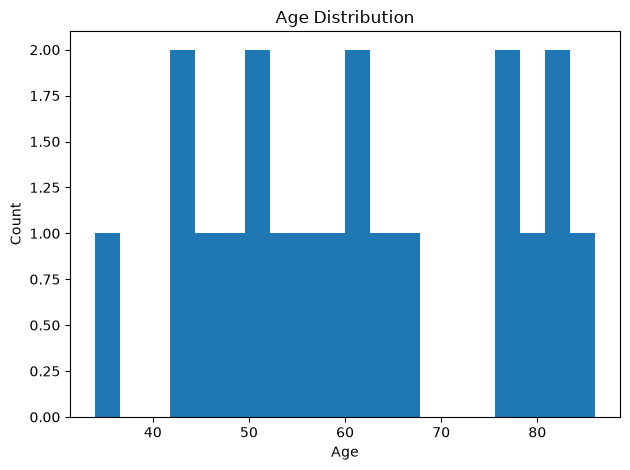

In [18]:
# Optional Python visualization workspace
import matplotlib.pyplot as plt

if "anchor_age" in project_df.columns:
    project_df["anchor_age"].dropna().plot(kind="hist", bins=20)
    plt.title("Age Distribution")
    plt.xlabel("Age")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

## Step 8 — Tableau Export

Export a cleaned or summarized dataset for Tableau. Do not export restricted or unnecessary row-level data.

In [19]:
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

export_path = output_dir / "group_project_tableau_export.csv"
project_df.to_csv(export_path, index=False)

print(f"Exported: {export_path}")

Exported: outputs/group_project_tableau_export.csv


## Step 9 — Tableau Dashboard Notes

Document the dashboard design.

**Audience:**  

**Dashboard purpose:**  

**KPI cards:**  

**Filters:**  

**Worksheets:**  

**Primary recommendation supported by dashboard:**

## Step 10 — Findings and Recommendations

### Key Findings

1.  
2.  
3.  

### Interpretation


### Recommendation


### Limitations

1.  
2.  
3.

## Clinical Decision Point

If you were presenting to the Chief Medical Information Officer tomorrow, what single recommendation would your team make based on your analysis?

Your answer should include:

- the evidence supporting the recommendation;
- the uncertainty or limitation that matters most;
- the next data or workflow question you would investigate; and
- the stakeholder who should act on the recommendation.

## Final Presentation Checklist

- [ ] Clinical question is clear
- [ ] Dataset and cohort are described
- [ ] Methods are understandable
- [ ] SQL and Python workflow is reproducible
- [ ] Dashboard answers the question
- [ ] Findings are specific
- [ ] Recommendation is actionable
- [ ] Limitations are transparent
- [ ] All team members participate
- [ ] Presentation stays within assigned time

## Repository Checklist

Your final repository or submitted folder should include:

- [ ] README.md
- [ ] Project notebook
- [ ] SQL script or documented SQL queries
- [ ] Data dictionary
- [ ] Data cleaning log
- [ ] Tableau workbook or dashboard file
- [ ] Dashboard PDF or screenshots
- [ ] Presentation slides
- [ ] Any required reflection documents

## Individual Reflection

Each student should answer:

1. What was your role on the team?
2. What was the most valuable thing you learned?
3. What was the most challenging part of the project?
4. Which tool added the most value: SQL, Python, or Tableau?
5. What would you do differently next time?
6. How has your understanding of health informatics changed?

## Closing

At the beginning of the course, you learned how to ask meaningful healthcare questions. You then learned how to evaluate data quality, retrieve data with SQL, prepare and explore data with Python, and communicate findings with Tableau.

The Group Project is your opportunity to integrate these skills into a professional health informatics analysis.

The tools are important, but your greatest contribution is your ability to transform data into decisions that improve healthcare.

In [ ]:
# Close database connections when finished.
engine.dispose()
print("Database connection closed.")